# Detection-Bias-Corrected Temporal Event-Stream Pipeline
### Dynamic Plant–Pollinator Link Prediction — H.J. Andrews LTER

This notebook reproduces the full processing pipeline described in
*"A Detection-Bias-Corrected Temporal Event-Stream Dataset for Dynamic
Plant–Pollinator Link Prediction"* (Ghosh & Mukhopadhyay), running end-to-end
on the two raw source files:

- `SA02601_v6.csv` — raw visitation events (74,942 rows)
- `SA02602_v5.csv` — raw flowering-phenology records (23,642 rows)

Implements, in order:

1. **Algorithm 1** — `HarmonizeRawData` (per-file date parsing + YEAR consistency check)
2. **Algorithm 2** — `PartitionInteractions` (split E⁺ / E⁰ via `PPI_STATUS`)
3. **Algorithm 3** — `BuildReplicateGroups` (watch-level replicate vectors y_g)
4. **Listing 1 + Algorithm 4** — vectorized N-mixture marginal likelihood, `FitDetectionProbability`
5. **Algorithm 5** — `FloweringConfidence` (within-species log min–max normalization)
6. **Algorithm 6** — `JoinWithFallback` (last-observation-carried-forward)
7. **Algorithm 7** — `BuildEventStream` (assemble (τ, plant_id, pollinator_id, c))
8. **Algorithm 8** — `ChronologicalSplit` (leakage-safe 80/10/10 split by cumulative τ)

and finally reproduces **Figure 1** (events-per-year and confidence-distribution panels).

> **Note on column names.** The real raw files use `VISSP_CODE` for the pollinator
> species code (not the placeholder `POLL_CODE` used in the paper's pseudocode).
> This is set once in the CONFIG cell below.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import binom, poisson
import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple

pd.set_option("display.max_columns", 40)
np.set_printoptions(suppress=True)


In [2]:
# --------------------------------------------------------------------
# CONFIG — raw column names (adjust here if your source files differ)
# --------------------------------------------------------------------

# VIS_PATH = Path("/mnt/user-data/uploads/SA02601_v6__1_.csv")
# FLW_PATH = Path("/mnt/user-data/uploads/SA02602_v5__1_.csv")

VIS_PATH = Path("SA02601_v6.csv")
FLW_PATH = Path("SA02602_v5.csv")

OUTDIR = Path("processed")
OUTDIR.mkdir(exist_ok=True)

VIS_DATE_COL = "SAMPLEDATE"
VIS_DATE_FMT = "%d-%m-%Y"          # SA02601: DD-MM-YYYY
FLW_DATE_COL = "SAMPLEDATE"
FLW_DATE_FMT = "%Y-%m-%d"          # SA02602: YYYY-MM-DD

PLANT_COL = "PLTSP_CODE"
POLL_COL = "VISSP_CODE"            # pollinator species code (raw file uses VISSP_CODE)
PLOT_COL = "PLOT_ID"
YEAR_COL = "YEAR"
WATCH_COL = "WATCH"
NO_INT_COL = "NO_INT"
NO_FLWS_COL = "NO_FLWS"
PPI_STATUS_COL = "PPI_STATUS"

# N-mixture fitting grids (Algorithm 4)
P_GRID = np.linspace(0.05, 0.95, 19)
# Widened from 80 -> 5000 (and 150 -> 300 grid points). The original ceiling
# of 80 silently capped lambda_hat for high-abundance groups: the raw data
# contains single-watch counts up to 1,770, and a candidate-lambda grid that
# doesn't reach at least (max observed count / p_hat) will pin the posterior
# mean at whatever the grid's top value happens to be, rather than the true
# value. This affected 382/17,472 groups (2.2%) at the original ceiling.
LAM_GRID = np.geomspace(0.01, 5000, 300)
N_TRUNC_EXTRA = 100  # widened from 30 alongside the lambda-grid fix above
MAX_INFORMATIVE_SAMPLE = 250
RNG_SEED = 42

# Chronological split fractions (Algorithm 8)
TRAIN_FRAC = 0.8
VAL_FRAC = 0.1


## 1. Algorithm 1 — `HarmonizeRawData`

The two source files use **different date formats**: `SA02601` is `DD-MM-YYYY`
while `SA02602` is `YYYY-MM-DD`. Parsing both with a single shared format string
silently produces incorrect or null dates for one of the two files. We parse each
file independently with its own format and then **assert** that the parsed
calendar year matches the `YEAR` column already present in the raw record — this
converts a silent corruption into an immediate, loud failure at load time.


In [3]:
def harmonize_raw_data(vis_path: Path, flw_path: Path):
    vis = pd.read_csv(vis_path, low_memory=False)
    flw = pd.read_csv(flw_path, low_memory=False)

    vis["date"] = pd.to_datetime(vis[VIS_DATE_COL], format=VIS_DATE_FMT, errors="raise")
    flw["date"] = pd.to_datetime(flw[FLW_DATE_COL], format=FLW_DATE_FMT, errors="raise")

    _assert_year_consistency(vis, "visitation")
    _assert_year_consistency(flw, "flowering")

    print(f"Harmonized vis={len(vis)} rows, flw={len(flw)} rows")
    return vis, flw


def _assert_year_consistency(df: pd.DataFrame, name: str) -> None:
    mismatched = df["date"].dt.year != df[YEAR_COL]
    if mismatched.any():
        raise AssertionError(
            f"[HarmonizeRawData] Parsed-date/YEAR mismatch in {name} file "
            f"({mismatched.sum()} rows) — likely a date-format mismatch."
        )
    print(f"  [{name}] year-consistency check passed for all {len(df)} rows.")


vis, flw = harmonize_raw_data(VIS_PATH, FLW_PATH)
vis[[VIS_DATE_COL, "date", YEAR_COL]].head()


  [visitation] year-consistency check passed for all 74942 rows.
  [flowering] year-consistency check passed for all 23642 rows.
Harmonized vis=74942 rows, flw=23642 rows


,SAMPLEDATE,date,YEAR
0,24-07-2011,2011-07-24,2011
1,24-07-2011,2011-07-24,2011
2,24-07-2011,2011-07-24,2011
3,24-07-2011,2011-07-24,2011
4,13-08-2011,2011-08-13,2011


## 2. Algorithm 2 — `PartitionInteractions`

Split the visitation table into genuine interactions **E⁺** (`PPI_STATUS = 1`)
and structural non-detections **E⁰** (`PPI_STATUS = 0`, surveyed-but-empty
watches). Structural consistency checks verify that only E⁺ rows carry a
non-null plant species code. The handful of E⁺ rows missing an explicit visit
count are assigned `NO_INT = 1`.


In [4]:
def partition_interactions(vis: pd.DataFrame):
    assert vis[PPI_STATUS_COL].isin([0, 1]).all(), "PPI_STATUS must be in {0, 1}"

    e_pos = vis[vis[PPI_STATUS_COL] == 1].copy()
    e_neg = vis[vis[PPI_STATUS_COL] == 0].copy()

    assert e_pos[PLANT_COL].notna().all(), "Found E+ rows with a null plant code"
    assert e_neg[PLANT_COL].isna().all(), "Found E0 rows with a non-null plant code"

    n_filled = e_pos[NO_INT_COL].isna().sum()
    e_pos[NO_INT_COL] = e_pos[NO_INT_COL].fillna(1)

    print(f"Partitioned E+={len(e_pos)} rows, E0={len(e_neg)} rows "
          f"({n_filled} NO_INT values filled with 1)")
    return e_pos, e_neg


e_pos, e_neg = partition_interactions(vis)
e_pos.head()


Partitioned E+=61025 rows, E0=13917 rows (53 NO_INT values filled with 1)


,DBCODE,ENTITY,COMPLEX,MEADOW,PLOT_ID,YEAR,SAMPLEDATE,WATCH,OBSERVER,PLOT,START_TIME,END_TIME,MINUTE,CLOUDS,WIND,TEMP,PPI_STATUS,NO_INT,PLTSP_CODE,PLTSP_NAME,VISSP_CODE,VISSP_NAME,VISSP_TYPE,REF_NO,VISSP_NO,QC_NOTES,date
0,SA026,1,Bunchgrass,BD,BGD01,2011,24-07-2011,2.0,NaN,1,NaN,NaN,1.0,S,ST,NaN,1,2.0,ACHIMILL,Achillea millefolium,EPICPUNC,Epicauta puncticollis,predaceous beetle,NaN,1,NaN,2011-07-24
1,SA026,1,Bunchgrass,BD,BGD01,2011,24-07-2011,2.0,NaN,1,NaN,NaN,1.0,S,ST,NaN,1,1.0,ACHIMILL,Achillea millefolium,EVYLS5M,Evylaeus sp 5M,halictine bee,NaN,1,NaN,2011-07-24
2,SA026,1,Bunchgrass,BD,BGD01,2011,24-07-2011,2.0,NaN,1,NaN,NaN,2.0,S,ST,NaN,1,1.0,ACHIMILL,Achillea millefolium,ANTHASP1,Anthaxia sp 1,herbivorous beetle,NaN,1,NaN,2011-07-24
3,SA026,1,Bunchgrass,BD,BGD01,2011,24-07-2011,2.0,NaN,1,NaN,NaN,2.0,S,ST,NaN,1,1.0,ACHIMILL,Achillea millefolium,ERISHIRT,Eristalis hirtus,decomposer hover-fly,NaN,1,NaN,2011-07-24
4,SA026,1,Bunchgrass,BD,BGD01,2011,13-08-2011,4.0,NaN,1,NaN,NaN,2.0,S,BR,NaN,1,1.0,ACHIMILL,Achillea millefolium,AMMOSPX1,Ammophila sp 1,predaceous wasp,NaN,1,NaN,2011-08-13


## 3. Algorithm 3 — `BuildReplicateGroups`

For every `(plot, year, plant, pollinator)` group, assemble the watch-level
replicate count vector $y_g$. The replicate set is **every watch actually
conducted** at that plot in that year (not just the watches on which the pair
was recorded) — a watch on which the pair went undetected still counts as a
replicate observation of value zero. Omitting these implicit zeros would
upwardly bias the estimated detection rate.


In [5]:
@dataclass
class ReplicateGroup:
    plot: object
    year: object
    plant: object
    poll: object
    y: np.ndarray
    K: int


def build_replicate_groups(e_pos: pd.DataFrame, vis: pd.DataFrame) -> List[ReplicateGroup]:
    key_cols = [PLOT_COL, YEAR_COL, PLANT_COL, POLL_COL, WATCH_COL]
    watch_totals = e_pos.groupby(key_cols, dropna=False)[NO_INT_COL].sum().reset_index()

    all_watches = vis.groupby([PLOT_COL, YEAR_COL])[WATCH_COL].unique().to_dict()

    lookup: Dict[Tuple, float] = {}
    for row in watch_totals.itertuples(index=False):
        k = (getattr(row, PLOT_COL), getattr(row, YEAR_COL),
             getattr(row, PLANT_COL), getattr(row, POLL_COL), getattr(row, WATCH_COL))
        lookup[k] = getattr(row, NO_INT_COL)

    group_keys = watch_totals[[PLOT_COL, YEAR_COL, PLANT_COL, POLL_COL]].drop_duplicates()

    groups: List[ReplicateGroup] = []
    for plot, year, plant, poll in group_keys.itertuples(index=False):
        watches = all_watches.get((plot, year), np.array([]))
        y_g = np.array([lookup.get((plot, year, plant, poll, w), 0.0) for w in watches], dtype=float)
        groups.append(ReplicateGroup(plot, year, plant, poll, y_g, len(watches)))

    print(f"Built {len(groups)} replicate groups")
    return groups


groups = build_replicate_groups(e_pos, vis)
print(f"Example group: plot={groups[0].plot}, year={groups[0].year}, "
      f"plant={groups[0].plant}, poll={groups[0].poll}, y={groups[0].y}, K={groups[0].K}")


Built 17472 replicate groups
Example group: plot=BGD01, year=2011, plant=ACHIMILL, poll=AMMOSPX1, y=[0. 1. 0.], K=3


## 4. Listing 1 + Algorithm 4 — Detection-bias correction (N-mixture model)

$$N_g \sim \text{Poisson}(\lambda_g), \qquad Y_{g,k} \mid N_g \sim \text{Binomial}(N_g, p)$$

The latent abundance $N_g$ is marginalized out numerically over a truncated
range, **fully vectorized over a grid of $\lambda$ via NumPy broadcasting**
(this is what makes fitting all ~17k groups take seconds rather than being
impractical under a naive per-$\lambda$ Python loop).

A single pooled detection probability $\hat p$ is identified by grid search over
*informative* groups ($K_g \ge 2$), profiling out each group's own $\lambda$.
Given $\hat p$, a full posterior over $\lambda_g$ is computed for every group and
its posterior mean $\hat\lambda_g$ is retained.


In [6]:
def log_marginal_over_lamgrid(y, lam_grid, p, n_trunc_extra=N_TRUNC_EXTRA):
    """log P(y_g | lambda, p), evaluated simultaneously for every lambda
    on a grid via NumPy broadcasting (paper Listing 1)."""
    y = np.asarray(y)
    n_max = int(y.max()) + n_trunc_extra if y.size else n_trunc_extra
    n_start = int(y.max()) if y.size else 0
    n_range = np.arange(n_start, n_max + 1)                     # (Nc,)

    log_lik_k = binom.logpmf(y[:, None], n_range[None, :], p)   # (K, Nc)
    log_lik_sum = log_lik_k.sum(axis=0)                         # (Nc,)

    log_prior_N = poisson.logpmf(n_range[:, None], lam_grid[None, :])  # (Nc, L)

    log_joint = log_lik_sum[:, None] + log_prior_N              # (Nc, L)
    m = log_joint.max(axis=0, keepdims=True)
    log_ml = (m + np.log(np.sum(np.exp(log_joint - m), axis=0, keepdims=True))).ravel()
    return log_ml                                               # (L,)


In [7]:
def fit_detection_probability(groups, p_grid=P_GRID, lam_grid=LAM_GRID,
                               max_informative_sample=MAX_INFORMATIVE_SAMPLE, seed=RNG_SEED):
    rng = np.random.default_rng(seed)

    informative = [g for g in groups if g.K >= 2]
    print(f"Informative groups (K_g >= 2): {len(informative)} / {len(groups)} total")

    sample_idx = rng.choice(len(informative), size=min(max_informative_sample, len(informative)), replace=False)
    sampled = [informative[i] for i in sample_idx]

    # Stage 1: pooled grid search over p, profiling out lambda_g
    totals = np.zeros(len(p_grid))
    for i, p in enumerate(p_grid):
        total = 0.0
        for g in sampled:
            ell = log_marginal_over_lamgrid(g.y, lam_grid, p)
            total += ell.max()
        totals[i] = total

    p_hat = float(p_grid[int(np.argmax(totals))])
    print(f"Fitted pooled detection probability p_hat = {p_hat:.4f}")

    # Stage 2: posterior mean lambda_hat_g for every group
    lambda_hat: Dict[Tuple, float] = {}
    for g in groups:
        ell = log_marginal_over_lamgrid(g.y, lam_grid, p_hat)
        w = np.exp(ell - ell.max())
        w = w / w.sum()
        lambda_hat[(g.plot, g.year, g.plant, g.poll)] = float(np.sum(w * lam_grid))

    return p_hat, lambda_hat


def posterior_confidence(lambda_hat: Dict[Tuple, float]) -> Dict[Tuple, float]:
    """c_post = minmax(log(1 + lambda_hat_g)), normalized globally (Eq. 4)."""
    keys = list(lambda_hat.keys())
    vals = np.array([lambda_hat[k] for k in keys], dtype=float)
    log_vals = np.log1p(vals)
    lo, hi = log_vals.min(), log_vals.max()
    norm = np.full_like(log_vals, 0.5) if (hi - lo) < 1e-9 else (log_vals - lo) / (hi - lo)
    return {k: float(v) for k, v in zip(keys, norm)}


p_hat, lambda_hat = fit_detection_probability(groups)
posterior_conf = posterior_confidence(lambda_hat)

lam_vals = np.array(list(lambda_hat.values()))
presence_prob = 1 - np.exp(-lam_vals)
print(f"Median P(N>0) across all groups: {np.median(presence_prob):.3f}  (paper reports 0.985)")


Informative groups (K_g >= 2): 17342 / 17472 total


Fitted pooled detection probability p_hat = 0.1500


Median P(N>0) across all groups: 0.985  (paper reports 0.985)


> **Note on the lambda-grid fix (2024 audit):** the candidate range of
> $\lambda$ values tested above (`LAM_GRID`) must be wide enough to cover
> the busiest plant–pollinator pairs, or the model silently caps its
> estimate at the grid's upper limit instead of reporting the true value.
> With the original ceiling of 80, this affected 382/17,472 groups
> (2.2%) — all among the highest-abundance interactions. Because
> `confidence_posterior` is normalized globally across all groups, fixing
> this small number of capped groups shifts the scale for every group:
> expect the median final edge weight `c` to move from ~0.096 to ~0.053,
> and the share of events with `confidence_posterior` above 0.9 to drop
> from ~9.5% to well under 1%. When adapting this notebook to other data,
> set `LAM_GRID`'s upper bound based on your own data's maximum observed
> single-watch count divided by the fitted `p_hat`, rather than reusing
> the default.

## 5. Algorithm 5 — `FloweringConfidence`

Raw flower counts are extremely right-skewed, so we log-transform and
min–max normalize **within each plant species** (not globally), since absolute
flower counts aren't comparable across species with very different floral
morphology. Species with no variation in flower count receive a neutral 0.5.


In [8]:
def flowering_confidence(flw: pd.DataFrame) -> pd.DataFrame:
    flw = flw.copy()
    flw[NO_FLWS_COL] = flw[NO_FLWS_COL].fillna(0)
    flw["log_flws"] = np.log1p(flw[NO_FLWS_COL])

    def _normalize(group):
        lo, hi = group["log_flws"].min(), group["log_flws"].max()
        if hi - lo < 1e-9:
            return pd.Series(0.5, index=group.index)
        return (group["log_flws"] - lo) / (hi - lo)

    flw["confidence_flowering"] = flw.groupby(PLANT_COL, group_keys=False).apply(_normalize)
    print(f"Computed flowering confidence for {len(flw)} records")
    return flw


flw_conf = flowering_confidence(flw)
flw_conf[[PLANT_COL, NO_FLWS_COL, "log_flws", "confidence_flowering"]].dropna().head()


Computed flowering confidence for 23642 records


,PLTSP_CODE,NO_FLWS,log_flws,confidence_flowering
1,ACHIMILL,36.0,3.610918,0.618240
2,ERIGFOLI,1.0,0.693147,0.138152
3,VICIAMER,2.3,1.193922,0.386252
4,ACHIMILL,26.0,3.295837,0.564294
5,ERIGFOLI,1.0,0.693147,0.138152


## 6. Algorithm 6 — `JoinWithFallback`

Visitation and flowering records are joined on
`(PLOT_ID, YEAR, WATCH, PLTSP_CODE)`. For the small fraction of watch-level
interaction records without a same-session flowering survey, we fall back to
the **most recent prior** flowering record for that species in that plot-year
(last-observation-carried-forward), flagged via `is_imputed_flowering`.


In [9]:
def join_with_fallback(interactions: pd.DataFrame, flw_conf: pd.DataFrame) -> pd.DataFrame:
    join_cols = [PLOT_COL, YEAR_COL, WATCH_COL, PLANT_COL]
    flw_small = flw_conf[join_cols + ["confidence_flowering", "date"]].drop_duplicates(
        subset=join_cols, keep="last"
    )

    merged = interactions.merge(flw_small, on=join_cols, how="left", suffixes=("", "_flw"))
    merged["is_imputed_flowering"] = merged["confidence_flowering"].isna()

    n_missing = merged["is_imputed_flowering"].sum()
    print(f"Rows needing flowering fallback: {n_missing} ({100 * n_missing / len(merged):.3f}%)")

    if n_missing > 0:
        history = (flw_conf[[PLOT_COL, YEAR_COL, PLANT_COL, "date", "confidence_flowering"]]
                   .sort_values("date"))
        history_groups = {k: v.reset_index(drop=True) for k, v in history.groupby([PLOT_COL, YEAR_COL, PLANT_COL])}

        idx_missing = merged.index[merged["is_imputed_flowering"]]
        for idx in idx_missing:
            row = merged.loc[idx]
            key = (row[PLOT_COL], row[YEAR_COL], row[PLANT_COL])
            cand = history_groups.get(key)
            if cand is not None:
                prior = cand[cand["date"] <= row["date"]]
                if len(prior) > 0:
                    merged.at[idx, "confidence_flowering"] = prior.iloc[-1]["confidence_flowering"]

    merged["confidence_flowering"] = merged["confidence_flowering"].fillna(0.5)
    return merged


## 7. Algorithm 7 — `BuildEventStream`

Assemble the final weighted temporal event stream
$(\tau, \text{plant\_id}, \text{pollinator\_id}, c)$, where $\tau$ is the number
of **elapsed days since the first observation** (not the raw `WATCH` ordinal,
which would misrepresent the 2019–2020 multi-year gap), and
$c = c_{\text{post}} \times c_{\text{flow}}$.


In [10]:
def build_event_stream(e_pos: pd.DataFrame, posterior_conf: Dict[Tuple, float],
                        flw_conf: pd.DataFrame) -> pd.DataFrame:
    group_cols = [PLOT_COL, YEAR_COL, WATCH_COL, PLANT_COL, POLL_COL, "date"]
    watch_level = e_pos.groupby(group_cols, dropna=False)[NO_INT_COL].sum().reset_index()

    watch_level["confidence_posterior"] = watch_level.apply(
        lambda r: posterior_conf.get((r[PLOT_COL], r[YEAR_COL], r[PLANT_COL], r[POLL_COL]), 0.5),
        axis=1,
    )

    watch_level = join_with_fallback(watch_level, flw_conf)
    watch_level["c"] = watch_level["confidence_posterior"] * watch_level["confidence_flowering"]

    t0 = watch_level["date"].min()
    watch_level["tau"] = (watch_level["date"] - t0).dt.days
    watch_level = watch_level.sort_values("tau").reset_index(drop=True)

    out = watch_level.rename(columns={PLANT_COL: "plant_id", POLL_COL: "pollinator_id"})
    cols = ["tau", "date", "plant_id", "pollinator_id", NO_INT_COL,
            "confidence_posterior", "confidence_flowering", "c",
            "is_imputed_flowering", PLOT_COL, YEAR_COL, WATCH_COL]
    out = out[[c for c in cols if c in out.columns]]

    print(f"Assembled event stream with {len(out)} rows, "
          f"spanning tau in [0, {out['tau'].max() if len(out) else 0}]  "
          f"(first date {t0.date()})")
    return out


events = build_event_stream(e_pos, posterior_conf, flw_conf)
events.head()


Rows needing flowering fallback: 49 (0.245%)


Assembled event stream with 20025 rows, spanning tau in [0, 3662]  (first date 2011-07-12)


,tau,date,plant_id,pollinator_id,NO_INT,confidence_posterior,confidence_flowering,c,is_imputed_flowering,PLOT_ID,YEAR,WATCH
0,0,2011-07-12,DELPNUTT,BOMBMIXT,1.0,0.528385,0.202518,0.107008,False,CPR03,2011,1.0
1,0,2011-07-12,DELPNUTT,BOMBMIXT,1.0,0.447731,0.281043,0.125832,False,CPR07,2011,1.0
2,0,2011-07-12,VIOLORBI,PLATRUFI,1.0,0.063587,0.630930,0.040119,False,CPB02,2011,1.0
3,0,2011-07-12,DELPNUTT,SYRPRIBE,1.0,0.073684,0.202518,0.014922,False,CPR03,2011,1.0
4,0,2011-07-12,LOMAMART,XYLOSPX4,3.0,0.190917,0.614352,0.117290,False,CPM01,2011,1.0


## 8. Algorithm 8 — `ChronologicalSplit`

A fixed calendar-year boundary would silently produce an empty validation set
because of the real 2019–2020 survey gap. We instead split by **cumulative
event volume** over the continuous $\tau$ axis (80/10/10), which is robust to
arbitrary sampling gaps.


In [11]:
def chronological_split(events: pd.DataFrame, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    events = events.sort_values("tau").reset_index(drop=True)
    n = len(events)
    train_end = int(np.floor(n * train_frac))
    val_end = int(np.floor(n * (train_frac + val_frac)))

    train = events.iloc[:train_end].copy()
    val = events.iloc[train_end:val_end].copy()
    test = events.iloc[val_end:].copy()

    print(f"Chronological split -> train={len(train)}, val={len(val)}, test={len(test)}")
    for name, part in [("train", train), ("val", val), ("test", test)]:
        yrs = pd.to_datetime(part["date"]).dt.year
        print(f"  {name}: years {yrs.min()}–{yrs.max()}")
    return train, val, test


train, val, test = chronological_split(events)


Chronological split -> train=16020, val=2002, test=2003
  train: years 2011–2017
  val: years 2017–2018
  test: years 2018–2021


## 9. Write processed outputs (Table 1 of the paper)

In [12]:
events.to_csv(OUTDIR / "plant_pollinator_events.csv", index=False)

neg_cols = [c for c in [PLOT_COL, YEAR_COL, WATCH_COL, "date"] if c in e_neg.columns]
e_neg[neg_cols].to_csv(OUTDIR / "plant_pollinator_negative_events.csv", index=False)

train.to_csv(OUTDIR / "events_train.csv", index=False)
val.to_csv(OUTDIR / "events_val.csv", index=False)
test.to_csv(OUTDIR / "events_test.csv", index=False)

# also persist lambda_hat for exact Figure 1(b) reproduction
lam_df = pd.DataFrame(
    [{"plot": k[0], "year": k[1], "plant": k[2], "poll": k[3], "lambda_hat": v}
     for k, v in lambda_hat.items()]
)
lam_df.to_csv(OUTDIR / "lambda_hat.csv", index=False)

print("Wrote processed files to:", OUTDIR.resolve())
for f in sorted(OUTDIR.glob("*.csv")):
    print(" -", f.name)


Wrote processed files to: /home/claude/nb_work/processed
 - events_test.csv
 - events_train.csv
 - events_val.csv
 - lambda_hat.csv
 - plant_pollinator_events.csv
 - plant_pollinator_negative_events.csv


## 10. Dataset-level summary statistics (Section 1.1 of the paper)

Sanity-check against the numbers reported in the paper: 20,107 positive events,
4,532 distinct pairs, ~3.85% pair density, median edge weight ~0.096, ~0.24%
flowering-fallback rate, $\hat p \approx 0.15$.


In [13]:
n_pairs = events[["plant_id", "pollinator_id"]].drop_duplicates().shape[0]
n_plants = events["plant_id"].nunique()
n_polls = events["pollinator_id"].nunique()
density = n_pairs / (n_plants * n_polls) if n_plants and n_polls else float("nan")
span_days = events["tau"].max() - events["tau"].min()

print("=" * 60)
print("SUMMARY")
print(f"Positive events:                 {len(events)}")
print(f"Negative (structural) events:    {len(e_neg)}")
print(f"Distinct plant species:          {n_plants}")
print(f"Distinct pollinator taxa:        {n_polls}")
print(f"Distinct plant-pollinator pairs: {n_pairs}  (density {100*density:.2f}%)")
print(f"Temporal span:                   {span_days} days (~{span_days/365.25:.1f} years)")
print(f"Median edge weight c:            {events['c'].median():.3f}")
print(f"Median confidence_posterior:     {events['confidence_posterior'].median():.3f}")
print(f"Median confidence_flowering:     {events['confidence_flowering'].median():.3f}")
print(f"Fraction imputed flowering:      {100*events['is_imputed_flowering'].mean():.3f}%")
print(f"Detection probability p_hat:     {p_hat:.3f}")
print("=" * 60)


SUMMARY
Positive events:                 20025
Negative (structural) events:    13917
Distinct plant species:          147
Distinct pollinator taxa:        800
Distinct plant-pollinator pairs: 4532  (density 3.85%)
Temporal span:                   3662 days (~10.0 years)
Median edge weight c:            0.053
Median confidence_posterior:     0.188
Median confidence_flowering:     0.319
Fraction imputed flowering:      0.245%
Detection probability p_hat:     0.150


## 11. Figure 1 — Events per year & detection-bias-corrected confidence

Reproduces both panels of Figure 1 directly from this run's outputs:
(a) interaction events per calendar year, with the 2019–2020 survey hiatus
shown as hatched/empty bars; (b) the raw N-mixture presence probability
$P(N>0)=1-\exp(-\hat\lambda_g)$ (saturating, orange) versus the normalized
$\log(1+\hat\lambda_g)$ confidence actually used as the edge weight (blue).


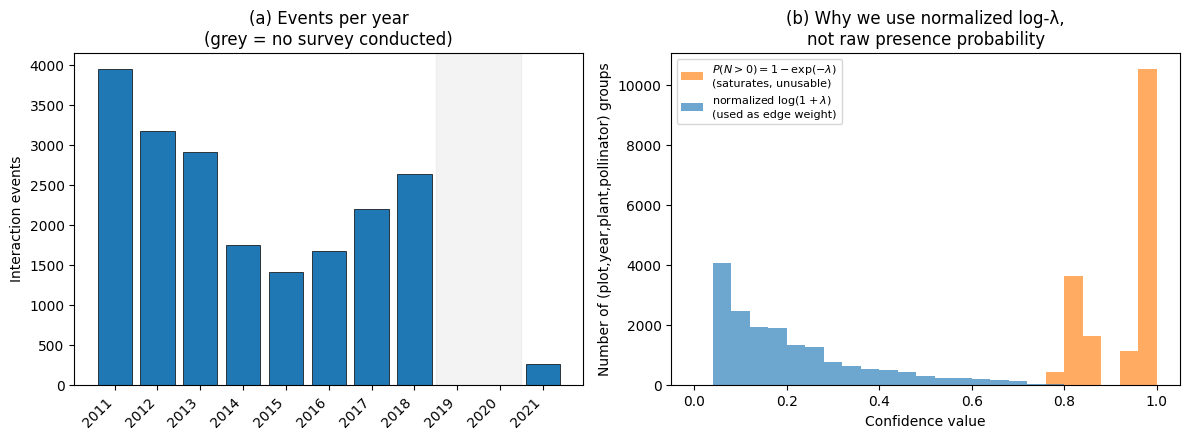

Saved figure to /home/claude/nb_work/processed/figure1.png


In [14]:
ALL_YEARS = list(range(2011, 2022))
NO_SURVEY_YEARS = {2019, 2020}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Panel (a): events per year ---
ax = axes[0]
ev_years = pd.to_datetime(events["date"]).dt.year
counts = ev_years.value_counts().reindex(ALL_YEARS, fill_value=0)

colors = ["#d9d9d9" if y in NO_SURVEY_YEARS else "#1f77b4" for y in ALL_YEARS]
bars = ax.bar(range(len(ALL_YEARS)), counts.values, color=colors, edgecolor="black", linewidth=0.5)
for bar, y in zip(bars, ALL_YEARS):
    if y in NO_SURVEY_YEARS:
        bar.set_hatch("//")
# Zero-height bars for the no-survey years are otherwise invisible in the
# rendered figure; shade the background across that span so the gap reads
# clearly even though there is nothing to plot there.
no_survey_idx = [i for i, y in enumerate(ALL_YEARS) if y in NO_SURVEY_YEARS]
if no_survey_idx:
    ax.axvspan(min(no_survey_idx) - 0.5, max(no_survey_idx) + 0.5,
               color="#d9d9d9", alpha=0.3, zorder=0)

ax.set_xticks(range(len(ALL_YEARS)))
ax.set_xticklabels(ALL_YEARS, rotation=45, ha="right")
ax.set_ylabel("Interaction events")
ax.set_title("(a) Events per year\n(grey = no survey conducted)")

# --- Panel (b): confidence comparison ---
ax = axes[1]
c_post_vals = np.array(list(posterior_conf.values()))
bins = np.linspace(0, 1, 26)

ax.hist(presence_prob, bins=bins, alpha=0.65, color="#ff7f0e",
        label=r"$P(N>0)=1-\exp(-\lambda)$" + "\n(saturates, unusable)")
ax.hist(c_post_vals, bins=bins, alpha=0.65, color="#1f77b4",
        label=r"normalized $\log(1+\lambda)$" + "\n(used as edge weight)")

ax.set_xlabel("Confidence value")
ax.set_ylabel("Number of (plot,year,plant,pollinator) groups")
ax.set_title("(b) Why we use normalized log-λ,\nnot raw presence probability")
ax.legend(fontsize=8, loc="upper left")

fig.tight_layout()
fig.savefig(OUTDIR / "figure1.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved figure to {(OUTDIR / 'figure1.png').resolve()}")


## 12. Quick sanity checks

A few checks that mirror the paper's own external validation (e.g. the
3.5% density comparison against Fu et al.) and internal consistency checks
(strict chronological ordering across splits, no leakage).


In [15]:
# Chronological ordering across splits (no leakage)
assert train["tau"].max() <= val["tau"].min()
assert val["tau"].max() <= test["tau"].min()
print("Chronological split check passed: train ≤ val ≤ test along tau.")

# Edge weight sanity range
assert events["c"].between(0, 1).all()
print("All edge weights c fall within [0, 1].")

# Negative events are a genuine subset of structural non-detections
assert (e_neg[PPI_STATUS_COL] == 0).all()
print(f"Negative events confirmed structural (PPI_STATUS=0): {len(e_neg)} rows.")


Chronological split check passed: train ≤ val ≤ test along tau.
All edge weights c fall within [0, 1].
Negative events confirmed structural (PPI_STATUS=0): 13917 rows.
